In [ ]:
# HÜCRE 1: Kurulum
!pip uninstall -y llama-cpp-python

!pip install llama-cpp-python \
  --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cu121

!pip install -U sentence-transformers huggingface_hub


Found existing installation: llama_cpp_python 0.3.16
Uninstalling llama_cpp_python-0.3.16:
  Successfully uninstalled llama_cpp_python-0.3.16
Looking in indexes: https://pypi.org/simple, https://abetlen.github.io/llama-cpp-python/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 551.3/551.3 MB 1.3 MB/s eta 0:00:00
  Using cached huggingface_hub-1.1.7-py3-none-any.whl.metadata (13 kB)


In [ ]:
from huggingface_hub import snapshot_download
from sentence_transformers import SentenceTransformer, util
import torch

# ---- 1) Embedding modelini önce sağlam şekilde indir ----
print("Embedding modeli indiriliyor / kontrol ediliyor (ytu-ce-cosmos/turkish-e5-large)...")

model_dir = snapshot_download(
    repo_id="ytu-ce-cosmos/turkish-e5-large",
    resume_download=True,      # Yarım kaldıysa devam eder
    max_workers=1              # Bağlantı sorunlarında daha stabil
)

print("✅ Model indirildi, klasör:", model_dir)

# ---- 2) SentenceTransformer ile yükle ----
device = "cuda" if torch.cuda.is_available() else "cpu"
device = "cuda" if torch.cuda.is_available() else "cpu"
embedding_model = SentenceTransformer("ytu-ce-cosmos/turkish-e5-large", device=device)


print(f"✅ Embedding modeli hazır (cihaz: {device}).")


Embedding modeli indiriliyor / kontrol ediliyor (ytu-ce-cosmos/turkish-e5-large)...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:942: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

✅ Model indirildi, klasör: /root/.cache/huggingface/hub/models--ytu-ce-cosmos--turkish-e5-large/snapshots/02e2362d503bbdeafcb17143b2165c0743f9fdb1
✅ Embedding modeli hazır (cihaz: cuda).


In [ ]:
# === HÜCRE 3: Sadece Q4 GGUF dosyasını indir + Gemma'yı yükle ===

from huggingface_hub import hf_hub_download, list_repo_files
from llama_cpp import Llama
import json, random, re

repo_id = "ytu-ce-cosmos/Turkish-Gemma-9b-T1-GGUF"

print("Depodaki dosyalar kontrol ediliyor...")
files = list_repo_files(repo_id)

# İçinde 'Q4' geçen .gguf dosyalarını bul
candidates = [f for f in files if f.endswith(".gguf") and "Q4" in f]

if not candidates:
    raise FileNotFoundError("Q4 quantized .gguf dosyası bulunamadı.")

model_file = candidates[0]
print(f"Seçilen dosya: {model_file}")

# Sadece bu dosyayı indir (yaklaşık 5–6 GB)
model_path = hf_hub_download(
    repo_id=repo_id,
    filename=model_file,
    resume_download=True   # Yarım kaldıysa devam eder
)

print("✅ İndirme tamamlandı. Model GPU'ya yükleniyor...")

llm = Llama(
    model_path=model_path,
    n_gpu_layers=-1,   # Tüm katmanları GPU'ya at
    n_ctx=2048,
    verbose=False
)

print("✅ Gemma modeli (llm) başarıyla yüklendi ve hazır!")


Depodaki dosyalar kontrol ediliyor...
Seçilen dosya: Turkish-Gemma-9b-T1.IQ4_NL.gguf


Turkish-Gemma-9b-T1.IQ4_NL.gguf:   0%|          | 0.00/5.48G [00:00<?, ?B/s]

✅ İndirme tamamlandı. Model GPU'ya yükleniyor...


llama_context: n_ctx_per_seq (2048) < n_ctx_train (8192) -- the full capacity of the model will not be utilized
llama_kv_cache_unified_iswa: using full-size SWA cache (ref: https://github.com/ggml-org/llama.cpp/pull/13194#issuecomment-2868343055)


✅ Gemma modeli (llm) başarıyla yüklendi ve hazır!


In [ ]:
# @title Gelişmiş Veri Üretimi v2 (Yeni Konular + Anlamsal Kontrol + Yeni Dosya)

from sentence_transformers import util
import torch
import json
import random
import re
import os

# --- Model Kontrolü ---
if 'llm' not in globals():
    print("UYARI: 'llm' (Gemma Modeli) hafızada bulunamadı.")
    print("Lütfen yukarıdaki 'Modelin Yüklenmesi' kodunu çalıştırdığından emin ol.")
else:
    print("✅ Gemma modeli (llm) hafızada mevcut, kullanılıyor.")

if 'embedding_model' not in globals():
    print("UYARI: 'embedding_model' bulunamadı. Anlamsal benzerlik kontrolü yapılmayacak.")
else:
    print("✅ embedding_model hafızada, anlamsal kontrol aktif.")

# --- Yardımcı Fonksiyonlar ---

def generate_qa_pair(topic):
    """Soru, Doğru Cevap, Yanlış Cevap üretir."""
    prompt = f"""
    Sen yardımsever bir öğretmensin. Aşağıdaki konuda lise seviyesinde, kısa ve basit bir bilgi sorusu sor.
    Ardından bu soruya bir tane 'Doğru Cevap' ve bir tane tamamen alakasız veya yanlış olan 'Yanlış Cevap' ver.

    Konu: {topic}

    Lütfen çıktıyı tam olarak şu formatta ver (başka bir şey yazma):
    Soru: [Buraya soruyu yaz]
    Doğru Cevap: [Buraya doğru cevabı yaz]
    Yanlış Cevap: [Buraya yanlış cevabı yaz]
    """

    try:
        response = llm(
            prompt,
            max_tokens=256,
            stop=["\n\n", "Konu:"],
            echo=False
        )
        return parse_output(response['choices'][0]['text'].strip(), topic)
    except NameError:
        print("HATA: 'llm' tanımlı değil. Lütfen model yükleme hücresini çalıştırın.")
        return None

def parse_output(text, topic):
    """Model çıktısını parçalar."""
    try:
        q_match = re.search(r"Soru:\s*(.*)", text)
        g_match = re.search(r"Doğru Cevap:\s*(.*)", text)
        b_match = re.search(r"Yanlış Cevap:\s*(.*)", text)
        if q_match and g_match and b_match:
            return {
                "topic": topic,
                "question": q_match.group(1).strip(),
                "good_answer": g_match.group(1).strip(),
                "bad_answer": b_match.group(1).strip()
            }
        return None
    except:
        return None

def is_semantically_similar(new_question, existing_questions, threshold=0.82):
    """
    Yeni soruyu, mevcut sorularla karşılaştırır (Cosine Similarity).
    Benzerlik oranı threshold'u geçerse True döner.
    """
    # embedding_model yoksa kontrol yapma
    if 'embedding_model' not in globals() or not existing_questions:
        return False

    # Yeni sorunun embedding'i
    new_emb = embedding_model.encode(new_question, convert_to_tensor=True)

    # Mevcut soruların embedding'leri
    existing_embs = embedding_model.encode(existing_questions, convert_to_tensor=True)

    # Cosine Similarity hesapla
    cosine_scores = util.cos_sim(new_emb, existing_embs)

    # En yüksek benzerlik skorunu bul
    max_score = torch.max(cosine_scores).item()

    if max_score > threshold:
        print(f"  -> Benzer soru tespit edildi (Benzerlik: {max_score:.2f}). Atlanıyor.")
        return True
    return False

# --- Ana İşlem Döngüsü ---

topics = ["Fizik", "Kimya", "Biyoloji", "Tarih", "Coğrafya", "Matematik", "Uzay", "Ekonomi"]
dataset = []
target_count = 100

questions_text_list = []

print(f"\n🚀 {target_count} adet benzersiz soru üretiliyor... (Hedef Dosya: dataset_v2.json)")

while len(dataset) < target_count:
    topic = topics[len(dataset) % len(topics)]

    result = generate_qa_pair(topic)

    if result:
        new_q = result['question']

        # 1. Basit String Kontrolü
        if new_q in questions_text_list:
            print("  -> Birebir aynı soru, atlanıyor.")
            continue

        # 2. Anlamsal Kontrol
        if len(dataset) > 5 and is_semantically_similar(new_q, questions_text_list):
            continue

        dataset.append(result)
        questions_text_list.append(new_q)
        print(f"[{len(dataset)+1}/{target_count}] ({topic}) {new_q}")
    else:
        print("Format hatası, tekrar deneniyor...")

# --- Kayıt İşlemi ---

train_set = dataset[:50]
test_set = dataset[50:]

output_data = {
    "train": train_set,
    "test": test_set
}

filename = 'dataset_v2.json'
with open(filename, 'w', encoding='utf-8') as f:
    json.dump(output_data, f, ensure_ascii=False, indent=4)

print(f"\n✅ Veri üretimi tamamlandı!")
print(f"📁 Dosya kaydedildi: {filename}")
print(f"📊 Eğitim Seti: {len(train_set)} örnek")
print(f"📊 Test Seti: {len(test_set)} örnek")


✅ Gemma modeli (llm) hafızada mevcut, kullanılıyor.
✅ embedding_model hafızada, anlamsal kontrol aktif.

🚀 100 adet benzersiz soru üretiliyor... (Hedef Dosya: dataset_v2.json)
Format hatası, tekrar deneniyor...
Format hatası, tekrar deneniyor...
[2/100] (Fizik) Yerçekimi nedir?
Format hatası, tekrar deneniyor...
Format hatası, tekrar deneniyor...
Format hatası, tekrar deneniyor...
[3/100] (Kimya) Suyun kimyasal formülü nedir?
[4/100] (Biyoloji) Fotosentez sırasında bitkiler hangi gazı kullanır?
[5/100] (Tarih) Osmanlı İmparatorluğu'nun kurucusu kimdir?
Format hatası, tekrar deneniyor...
[6/100] (Coğrafya) Dünyanın en uzun nehri hangisidir?
Format hatası, tekrar deneniyor...
[7/100] (Matematik) 2+2 kaç eder?
[8/100] (Uzay) Dünya'nın kaç tane doğal uydusu vardır?
[9/100] (Ekonomi) Türkiye'nin para birimi nedir?
Format hatası, tekrar deneniyor...
Format hatası, tekrar deneniyor...
Format hatası, tekrar deneniyor...
[10/100] (Fizik) Su neden mavi görünür?
  -> Benzer soru tespit edildi (Be

In [ ]:
# === Embedding üretimi: dataset_v3.json -> dataset_v3_with_embeddings.json ===

import json

# 1) Veri setini yükle
with open("dataset_v3.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Embedding boyutunu öğrenelim (sadece bilgi amaçlı)
d = embedding_model.get_sentence_embedding_dimension()
print(f"Embedding boyutu d = {d}")

splits = ["train", "test"]
fields = ["question", "good_answer", "bad_answer"]

all_texts = []
index_map = []  # Hangi embedding hangi kayda ait, bunu tutacağız

# 2) Tüm metinleri tek listede topla (daha hızlı ve pratik)
for split in splits:
    for i, item in enumerate(data[split]):
        for field in fields:
            all_texts.append(item[field])
            index_map.append((split, i, field))

print(f"Toplam {len(all_texts)} metin için embedding hesaplanacak...")

# 3) Embedding'leri hesapla
embeddings = embedding_model.encode(
    all_texts,
    batch_size=16,
    convert_to_numpy=True,
    normalize_embeddings=True  # Cosine similarity için normalize etmek iyi fikir
)

# 4) Embedding'leri tekrar data yapısına yerleştir
for (split, i, field), vec in zip(index_map, embeddings):
    key = field + "_embedding"  # örn: question_embedding
    data[split][i][key] = vec.tolist()  # JSON'a yazılabilmesi için listeye çeviriyoruz

# 5) Yeni dosyaya kaydet
output_file = "dataset_v3_with_embeddings.json"
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=4)

print(f"\n✅ Tüm embedding'ler üretildi ve '{output_file}' dosyasına kaydedildi.")
print(f"Örnek soru embedding boyutu: {len(data['train'][0]['question_embedding'])} (1*d vektör)")


Embedding boyutu d = 1024
Toplam 300 metin için embedding hesaplanacak...

✅ Tüm embedding'ler üretildi ve 'dataset_v3_with_embeddings.json' dosyasına kaydedildi.
Örnek soru embedding boyutu: 1024 (1*d vektör)


In [ ]:
# === HÜCRE A: Veriyi yükle ve (X, y) hazırla ===

import json
import numpy as np

with open("dataset_v3_with_embeddings.json", "r", encoding="utf-8") as f:
    data = json.load(f)

d = len(data["train"][0]["question_embedding"])
print("Temsil boyutu d =", d)

def build_split(split_data):
    xs = []
    ys = []
    for item in split_data:
        q = np.array(item["question_embedding"], dtype=np.float32)          # (d,)
        g = np.array(item["good_answer_embedding"], dtype=np.float32)      # (d,)
        b = np.array(item["bad_answer_embedding"], dtype=np.float32)       # (d,)

        # Pozitif örnek: (soru, iyi cevap) -> +1
        x_pos_core = np.concatenate([q, g])                                 # (2d,)
        # Negatif örnek: (soru, kötü cevap) -> -1
        x_neg_core = np.concatenate([q, b])                                 # (2d,)

        xs.append(x_pos_core)
        ys.append(1.0)

        xs.append(x_neg_core)
        ys.append(-1.0)

    X_core = np.stack(xs)                      # (2N, 2d)
    y = np.array(ys, dtype=np.float32)         # (2N,)

    # Bias terimi ekle: sonuna 1 koy
    bias = np.ones((X_core.shape[0], 1), dtype=np.float32)
    X = np.concatenate([X_core, bias], axis=1) # (2N, 2d+1)

    return X, y

X_train, y_train = build_split(data["train"])
X_test, y_test   = build_split(data["test"])

print("X_train shape:", X_train.shape)  # (100, 2d+1) yani (100, 2049)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


Temsil boyutu d = 1024
X_train shape: (100, 2049)
y_train shape: (100,)
X_test shape: (100, 2049)
y_test shape: (100,)


In [ ]:
# === HÜCRE B: Model, loss ve optimizasyon algoritmaları ===

import time
import numpy as np

# ---- İleri geçiş + loss + grad ----

def loss_and_grad(w, X, y):
    """
    w: (2d+1,)
    X: (N, 2d+1)
    y: (N,)
    """
    z = X @ w                    # (N,)
    y_hat = np.tanh(z)           # (N,)
    errors = y_hat - y           # (N,)
    loss = np.mean(errors**2)

    # dL/dw = mean( 2 (y_hat - y) * (1 - y_hat^2) * x )
    factor = 2 * errors * (1 - y_hat**2)     # (N,)
    grad = (factor[:, None] * X).mean(axis=0)  # (2d+1,)

    return loss, grad

def accuracy(w, X, y):
    z = X @ w
    y_hat = np.tanh(z)
    y_pred = np.where(y_hat >= 0, 1.0, -1.0)
    return float(np.mean(y_pred == y))


# ---- Gradient Descent (tam batch) ----

def train_gd(X_train, y_train, X_test, y_test, w0, lr=0.01, n_epochs=50):
    w = w0.copy()
    history = {k: [] for k in ['epochs','steps','times',
                               'train_loss','test_loss',
                               'train_acc','test_acc']}

    step = 0
    t0 = time.time()

    for epoch in range(1, n_epochs+1):
        # Tüm batch üzerinde gradient
        train_loss, grad = loss_and_grad(w, X_train, y_train)
        w -= lr * grad
        step += 1

        # Metrikler
        train_loss, _ = loss_and_grad(w, X_train, y_train)
        test_loss, _  = loss_and_grad(w, X_test, y_test)
        train_acc = accuracy(w, X_train, y_train)
        test_acc = accuracy(w, X_test, y_test)
        t = time.time() - t0

        for k, v in [
            ('epochs', epoch),
            ('steps', step),
            ('times', t),
            ('train_loss', train_loss),
            ('test_loss', test_loss),
            ('train_acc', train_acc),
            ('test_acc', test_acc),
        ]:
            history[k].append(v)

    return w, history


# ---- Stochastic Gradient Descent ----

def train_sgd(X_train, y_train, X_test, y_test, w0,
              lr=0.001, n_epochs=50, shuffle=True):
    rng = np.random.default_rng()
    w = w0.copy()
    N = X_train.shape[0]

    history = {k: [] for k in ['epochs','steps','times',
                               'train_loss','test_loss',
                               'train_acc','test_acc']}

    step = 0
    t0 = time.time()

    for epoch in range(1, n_epochs+1):
        indices = np.arange(N)
        if shuffle:
            rng.shuffle(indices)

        for i in indices:
            Xi = X_train[i:i+1]
            yi = y_train[i:i+1]
            _, grad = loss_and_grad(w, Xi, yi)
            w -= lr * grad
            step += 1

        # Epoch sonunda metrikler
        train_loss, _ = loss_and_grad(w, X_train, y_train)
        test_loss, _ = loss_and_grad(w, X_test, y_test)
        train_acc = accuracy(w, X_train, y_train)
        test_acc = accuracy(w, X_test, y_test)
        t = time.time() - t0

        for k, v in [
            ('epochs', epoch),
            ('steps', step),
            ('times', t),
            ('train_loss', train_loss),
            ('test_loss', test_loss),
            ('train_acc', train_acc),
            ('test_acc', test_acc),
        ]:
            history[k].append(v)

    return w, history


# ---- Adam ----

def train_adam(X_train, y_train, X_test, y_test, w0,
               lr=0.001, n_epochs=50,
               beta1=0.9, beta2=0.999, eps=1e-8,
               shuffle=True):

    rng = np.random.default_rng()
    w = w0.copy()
    N, D = X_train.shape

    m = np.zeros(D)
    v = np.zeros(D)

    history = {k: [] for k in ['epochs','steps','times',
                               'train_loss','test_loss',
                               'train_acc','test_acc']}

    step = 0
    t0 = time.time()
    t_adam = 0

    for epoch in range(1, n_epochs+1):
        indices = np.arange(N)
        if shuffle:
            rng.shuffle(indices)

        for i in indices:
            Xi = X_train[i:i+1]
            yi = y_train[i:i+1]
            _, grad = loss_and_grad(w, Xi, yi)

            t_adam += 1
            m = beta1 * m + (1 - beta1) * grad
            v = beta2 * v + (1 - beta2) * (grad**2)

            m_hat = m / (1 - beta1**t_adam)
            v_hat = v / (1 - beta2**t_adam)

            w -= lr * m_hat / (np.sqrt(v_hat) + eps)
            step += 1

        # Epoch sonunda metrikler
        train_loss, _ = loss_and_grad(w, X_train, y_train)
        test_loss, _ = loss_and_grad(w, X_test, y_test)
        train_acc = accuracy(w, X_train, y_train)
        test_acc = accuracy(w, X_test, y_test)
        t = time.time() - t0

        for k, v in [
            ('epochs', epoch),
            ('steps', step),
            ('times', t),
            ('train_loss', train_loss),
            ('test_loss', test_loss),
            ('train_acc', train_acc),
            ('test_acc', test_acc),
        ]:
            history[k].append(v)

    return w, history


# ---- 5 farklı w0 ile tüm algoritmalar ----

def run_all_algorithms(X_train, y_train, X_test, y_test,
                        n_inits=5, n_epochs=50,
                        lr_gd=0.01, lr_sgd=0.001, lr_adam=0.001):
    D = X_train.shape[1]
    all_results = {'GD': [], 'SGD': [], 'Adam': []}

    for init_id in range(n_inits):
        np.random.seed(init_id)
        w0 = np.random.randn(D) * 0.01

        print(f"\n=== Başlangıç {init_id+1}/{n_inits} ===")

        print("GD eğitiliyor...")
        w_gd, hist_gd = train_gd(X_train, y_train, X_test, y_test,
                                 w0, lr=lr_gd, n_epochs=n_epochs)
        print(f"GD son epoch -> train acc: {hist_gd['train_acc'][-1]:.3f}, "
              f"test acc: {hist_gd['test_acc'][-1]:.3f}")

        print("SGD eğitiliyor...")
        w_sgd, hist_sgd = train_sgd(X_train, y_train, X_test, y_test,
                                    w0, lr=lr_sgd, n_epochs=n_epochs)
        print(f"SGD son epoch -> train acc: {hist_sgd['train_acc'][-1]:.3f}, "
              f"test acc: {hist_sgd['test_acc'][-1]:.3f}")

        print("Adam eğitiliyor...")
        w_adam, hist_adam = train_adam(X_train, y_train, X_test, y_test,
                                       w0, lr=lr_adam, n_epochs=n_epochs)
        print(f"Adam son epoch -> train acc: {hist_adam['train_acc'][-1]:.3f}, "
              f"test acc: {hist_adam['test_acc'][-1]:.3f}")

        all_results['GD'].append(hist_gd)
        all_results['SGD'].append(hist_sgd)
        all_results['Adam'].append(hist_adam)

    return all_results



=== Başlangıç 1/5 ===
GD eğitiliyor...
GD son epoch -> train acc: 0.820, test acc: 0.560
SGD eğitiliyor...
SGD son epoch -> train acc: 0.880, test acc: 0.550
Adam eğitiliyor...
Adam son epoch -> train acc: 0.930, test acc: 0.590

=== Başlangıç 2/5 ===
GD eğitiliyor...
GD son epoch -> train acc: 0.800, test acc: 0.570
SGD eğitiliyor...
SGD son epoch -> train acc: 0.880, test acc: 0.600
Adam eğitiliyor...
Adam son epoch -> train acc: 0.920, test acc: 0.610

=== Başlangıç 3/5 ===
GD eğitiliyor...
GD son epoch -> train acc: 0.820, test acc: 0.580
SGD eğitiliyor...
SGD son epoch -> train acc: 0.920, test acc: 0.600
Adam eğitiliyor...
Adam son epoch -> train acc: 0.950, test acc: 0.590

=== Başlangıç 4/5 ===
GD eğitiliyor...
GD son epoch -> train acc: 0.820, test acc: 0.580
SGD eğitiliyor...
SGD son epoch -> train acc: 0.880, test acc: 0.560
Adam eğitiliyor...
Adam son epoch -> train acc: 0.930, test acc: 0.610

=== Başlangıç 5/5 ===
GD eğitiliyor...
GD son epoch -> train acc: 0.800, test a

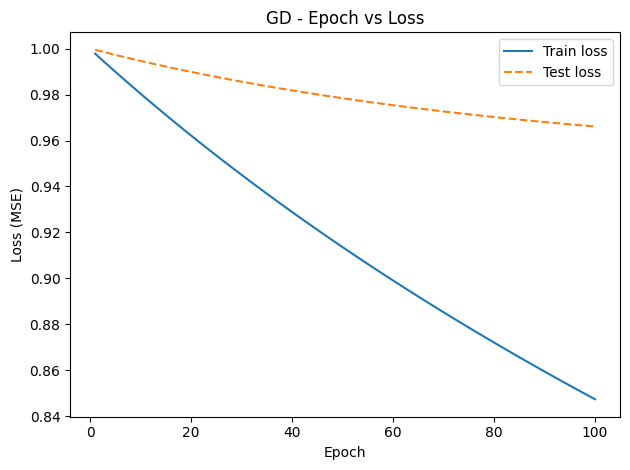

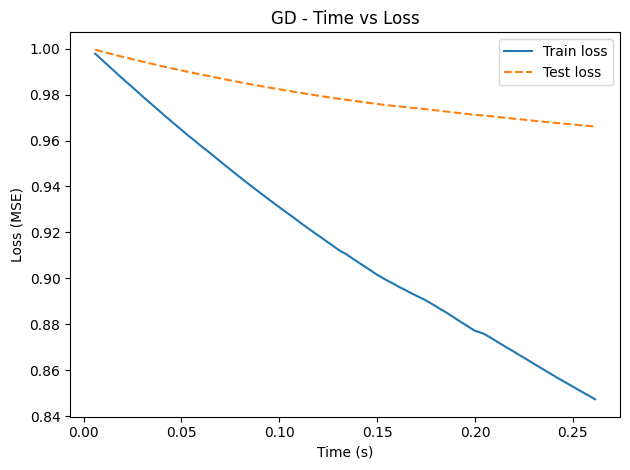

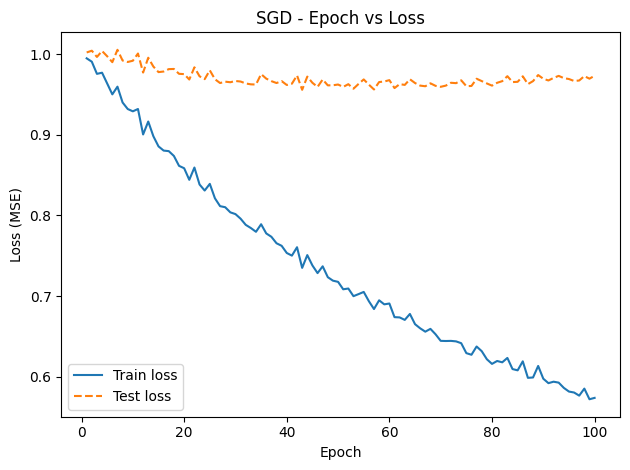

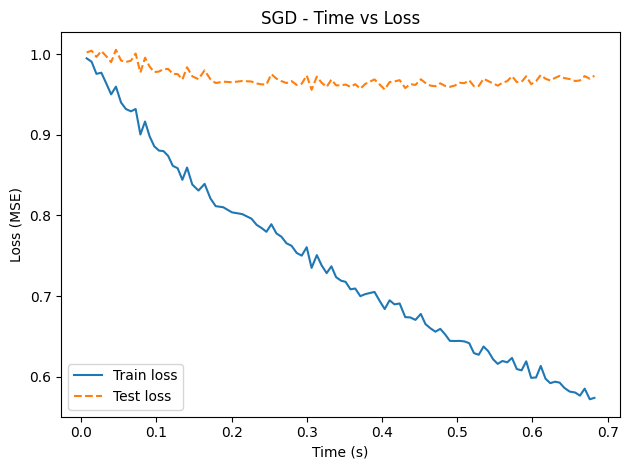

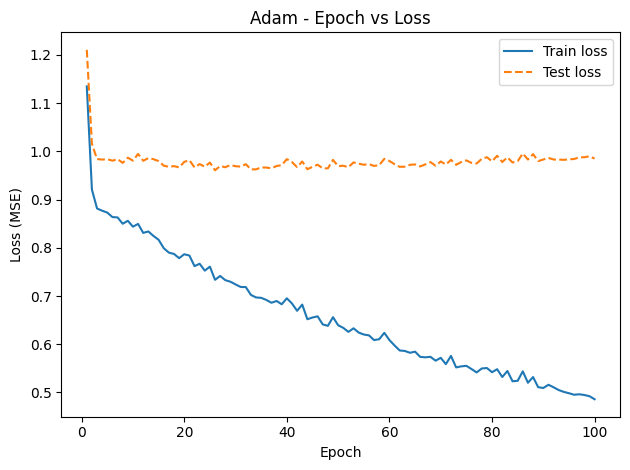

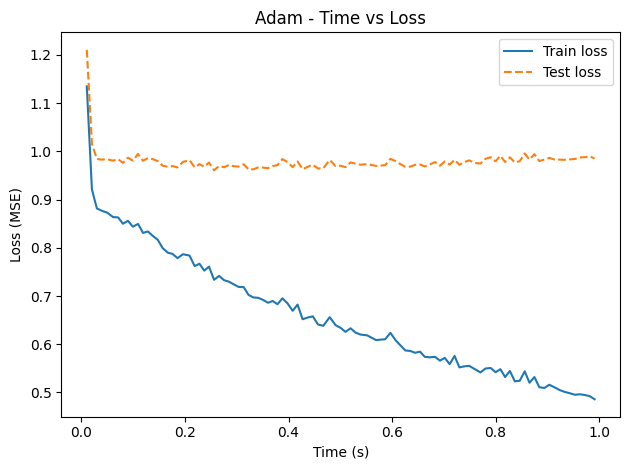

In [ ]:
# === YENİ HÜCRE C: Koş ve her yöntem için ayrı ayrı 6 grafik çiz ===

import matplotlib.pyplot as plt
import numpy as np

# 5 farklı w0 ile tüm algoritmaları çalıştır
all_results = run_all_algorithms(
    X_train, y_train, X_test, y_test,
    n_inits=5,
    lr_gd   = 0.2,
    lr_sgd  = 0.01,
    lr_adam = 0.01,
    n_epochs = 100
)

def aggregate_runs(runs):
    """
    5 koşudan ortalama:
      - train_loss, test_loss
      - train_acc, test_acc
    çıkar.
    Zaman ve epoch eksenlerini ilk koşudan alır.
    """
    keys_to_mean = ['train_loss', 'test_loss', 'train_acc', 'test_acc']
    agg = {}
    for k in keys_to_mean:
        arr = np.array([r[k] for r in runs])   # (n_runs, T)
        agg[k] = arr.mean(axis=0)             # (T,)

    # Epoch ve time eksenleri tüm run'larda aynı olduğu için ilkini alıyoruz
    for k in ['epochs', 'times']:
        agg[k] = runs[0][k]

    return agg

algos = ['GD', 'SGD', 'Adam']

for algo in algos:
    agg = aggregate_runs(all_results[algo])

    # ---- 1) Epoch vs Loss (train + test) ----
    plt.figure()
    plt.plot(agg['epochs'], agg['train_loss'], label='Train loss')
    plt.plot(agg['epochs'], agg['test_loss'], linestyle='--', label='Test loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss (MSE)')
    plt.title(f'{algo} - Epoch vs Loss')
    plt.legend()
    plt.tight_layout()

    # ---- 2) Time vs Loss (train + test) ----
    plt.figure()
    plt.plot(agg['times'], agg['train_loss'], label='Train loss')
    plt.plot(agg['times'], agg['test_loss'], linestyle='--', label='Test loss')
    plt.xlabel('Time (s)')
    plt.ylabel('Loss (MSE)')
    plt.title(f'{algo} - Time vs Loss')
    plt.legend()
    plt.tight_layout()

    # ---- 3) Epoch vs Accuracy (train + test) ----
    plt.figure()
    plt.plot(agg['epochs'], agg['train_acc'], label='Train accuracy')
    plt.plot(agg['epochs'], agg['test_acc'], linestyle='--', label='Test accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(f'{algo} - Epoch vs Accuracy')
    plt.legend()
    plt.tight_layout()

    # ---- 4) Time vs Accuracy (train + test) ----
    plt.figure()
    plt.plot(agg['times'], agg['train_acc'], label='Train accuracy')
    plt.plot(agg['times'], agg['test_acc'], linestyle='--', label='Test accuracy')
    plt.xlabel('Time (s)')
    plt.ylabel('Accuracy')
    plt.title(f'{algo} - Time vs Accuracy')
    plt.legend()
    plt.tight_layout()
